# Lab 1: Search 101, from string matching to search
**Course:** Information Retrieval (IR 2026), CADT  |  **Session 1**  |  **Time:** 3 hours  |  *Student version*

In the lecture you met the ideas of *information need*, *query* and *relevance*. In this lab you will build the simplest possible search tools, measure where they break, and use what you find to explain **why we need real IR techniques** (Sessions 2 to 10).

**By the end of this lab you can:**
1. Set up a Python and Jupyter environment for the course.
2. Implement keyword search three ways (substring scan, word match, SQLite `LIKE`) and compare them.
3. Judge relevance for an information need and compute precision and recall by hand.
4. Show, with measurements, why scanning every document does not scale.
5. Explain in your own words what a database query cannot do that a search engine must.

**How to work:** run the cells in order, replace every `# TODO`, and write your answers in the *Answer* cells. Pair up for Part 5 and Part 7, but write your own answers.

## Part 0. Setup (about 15 min)
**On your laptop** (Python 3.10 or newer), open a terminal in a new folder for this course:
```bash
python -m venv .venv
source .venv/bin/activate          # Windows: .venv\Scripts\activate
pip install jupyterlab pandas matplotlib
jupyter lab
```
**No install?** Upload this notebook to Google Colab. It already has everything needed.

Run the next cell. You should see your Python version and no errors.

In [3]:
import sys, sqlite3, re, time, random
import pandas as pd
import matplotlib.pyplot as plt

print("Python:", sys.version.split()[0])
print("SQLite:", sqlite3.sqlite_version)

Python: 3.14.6
SQLite: 3.53.4


## Part 1. The collection (about 10 min)
Our toy *collection* has 30 short documents about Cambodia, technology and everyday life. Some of them are deliberately tricky. Read all 30 once before you continue.

In [4]:
docs = {
    "d01": 'Budget guesthouses in Phnom Penh offer clean rooms near the Riverside for under twenty dollars a night.',
    "d02": 'Cheap hotel deals in Siem Reap are easy to find, especially during the rainy season.',
    "d03": 'The Cambodia Academy of Digital Technology offers degrees in software engineering, data science and cybersecurity.',
    "d04": 'Python is a popular programming language for data science, web development and automation.',
    "d05": 'A ball python is a small, docile snake that is often kept as a pet.',
    "d06": 'Java is a statically typed language widely used for enterprise applications and Android development.',
    "d07": 'Java is an island in Indonesia with more than one hundred million inhabitants.',
    "d08": 'Angkor Wat is the largest religious monument in the world and attracts millions of visitors every year.',
    "d09": 'The Mekong River flows through six countries and supports fishing and rice farming along its banks.',
    "d10": 'Rice is the main crop in Cambodia, and farmers plant it at the start of the rainy season.',
    "d11": 'Fried noodles and fish amok are popular dishes in Cambodian restaurants.',
    "d12": 'Buses run every hour from Phnom Penh to Siem Reap, and the trip takes about six hours.',
    "d13": 'Tuk-tuk drivers in the capital usually negotiate the fare before the ride starts.',
    "d14": 'Electric vehicles are becoming more common as battery prices fall.',
    "d15": 'An automobile engine converts fuel into motion using internal combustion.',
    "d16": 'Her cat sleeps all day, but at night it starts running around the house.',
    "d17": 'The library catalog lists every category of book, from fiction to computer science.',
    "d18": 'To concatenate two strings in Python, use the plus operator.',
    "d19": 'The marathon runners ran through the city streets despite the heat.',
    "d20": 'Apartments with 2 bedrooms near the university are popular with students.',
    "d21": 'Machine learning models learn patterns from data instead of following hand-written rules.',
    "d22": 'Search engines use crawlers to collect web pages and build an index for fast lookup.',
    "d23": 'A database stores structured records in tables and answers precise queries written in SQL.',
    "d24": 'The government announced new investment in digital skills and internet access for rural areas.',
    "d25": 'Coffee shops in the capital are popular places for students to study and meet friends.',
    "d26": 'Khmer script has no spaces between words, which makes text processing harder.',
    "d27": 'Airlines added more flights to the coastal city of Sihanoukville for the holiday season.',
    "d28": 'Learning to program requires regular practice, not only reading books.',
    "d29": 'The National Museum in Phnom Penh displays Khmer sculpture from the Angkorian period.',
    "d30": 'Affordable accommodation for backpackers is available in Kampot, including hostels and homestays.',
}

def show(ids):
    """Print the documents with the given ids."""
    if not ids:
        print("(no documents)")
    for i in ids:
        print(f"{i}: {docs[i]}")

pd.DataFrame({"id": list(docs), "text": list(docs.values())}).style.hide(axis="index")

id,text
d01,Budget guesthouses in Phnom Penh offer clean rooms near the Riverside for under twenty dollars a night.
d02,"Cheap hotel deals in Siem Reap are easy to find, especially during the rainy season."
d03,"The Cambodia Academy of Digital Technology offers degrees in software engineering, data science and cybersecurity."
d04,"Python is a popular programming language for data science, web development and automation."
d05,"A ball python is a small, docile snake that is often kept as a pet."
d06,Java is a statically typed language widely used for enterprise applications and Android development.
d07,Java is an island in Indonesia with more than one hundred million inhabitants.
d08,Angkor Wat is the largest religious monument in the world and attracts millions of visitors every year.
d09,The Mekong River flows through six countries and supports fishing and rice farming along its banks.
d10,"Rice is the main crop in Cambodia, and farmers plant it at the start of the rainy season."


## Part 2. Naive search, version 1: substring scan (about 30 min)
The simplest "search engine": check whether the query text appears inside each document.

In [5]:
from pydoc import doc


def search_substring(query, case_sensitive=False):
    """Return the ids of documents whose text contains `query` as a substring."""
    # TODO: loop over `docs`, compare (lower-case both sides unless case_sensitive), collect matching ids
    result = []

    for doc_id, text in docs.items():
        if case_sensitive:
            if query in text:
                result.append(doc_id)
        else:
            if query.lower() in text.lower():
                result.append(doc_id)

    return result


In [6]:
for q in ["cheap hotel", "python", "cat", "car", "running"]:
    hits = search_substring(q,case_sensitive=True)
    print(f"\nQuery: {q!r} -> {len(hits)} result(s)")
    show(hits)


Query: 'cheap hotel' -> 0 result(s)
(no documents)

Query: 'python' -> 1 result(s)
d05: A ball python is a small, docile snake that is often kept as a pet.

Query: 'cat' -> 4 result(s)
d06: Java is a statically typed language widely used for enterprise applications and Android development.
d16: Her cat sleeps all day, but at night it starts running around the house.
d17: The library catalog lists every category of book, from fiction to computer science.
d18: To concatenate two strings in Python, use the plus operator.

Query: 'car' -> 0 result(s)
(no documents)

Query: 'running' -> 1 result(s)
d16: Her cat sleeps all day, but at night it starts running around the house.


**Answer 2.1** For the query `cat`, which documents were returned? Which of them are really about cats? Why did the others match?

*Your answer:*

4 document were returned. only `d16` is really about cat and other not related. 
- for `d06` they match becase of word `application` contian string `cat`
- for `d17` word `catalog` also contain string `cat`
- for `d18` word `concatenate` also contain string `cat`


**Answer 2.2** Run `search_substring("python", case_sensitive=True)` and compare it with the case-insensitive result. Which is better, and is either one fully correct?

*Your answer:*

Case-insensitive search finds more documents (`d06,d16,17,18`) but also includes irrelevant results. but it better becuase user can chose what they need.


## Part 3. Naive search, version 2: whole-word match (about 25 min)
Substring matching finds `cat` inside `category`. Fix that by splitting text into *words* (tokens) and matching whole words. Support two modes: `AND` (all query words must appear) and `OR` (at least one).

In [7]:
def tokenize(text):
    """Lower-case the text and split it into words."""
    return re.findall(r"\w+", text.lower())

def search_words(query, mode="AND"):
    """Return ids of documents matching the query words as whole words."""
    # TODO: tokenize the query; for each document tokenize the text into a set;
    #       AND -> all query words present, OR -> any query word present
    query_words = tokenize(query)
    results = []

    for doc_id, doc_text in docs.items():
        doc_words = set(tokenize(doc_text))

        if mode == "AND":
            matched = True
            for word in query_words:
                if word not in doc_words:
                    matched = False
                    break

        elif mode == "OR":
            matched = False
            for word in query_words:
                if word in doc_words:
                    matched = True
                    break
        if matched:
            results.append(doc_id)

    return results

In [8]:
for q, mode in [("cat", "AND"), ("cheap hotel", "AND"), ("cheap hotel", "OR"),
                ("travel Phnom Penh Siem Reap", "AND"), ("travel Phnom Penh Siem Reap", "OR")]:
    hits = search_words(q, mode)
    print(f"\nQuery: {q!r} [{mode}] -> {len(hits)} result(s)")
    show(hits)


Query: 'cat' [AND] -> 1 result(s)
d16: Her cat sleeps all day, but at night it starts running around the house.

Query: 'cheap hotel' [AND] -> 1 result(s)
d02: Cheap hotel deals in Siem Reap are easy to find, especially during the rainy season.

Query: 'cheap hotel' [OR] -> 1 result(s)
d02: Cheap hotel deals in Siem Reap are easy to find, especially during the rainy season.

Query: 'travel Phnom Penh Siem Reap' [AND] -> 0 result(s)
(no documents)

Query: 'travel Phnom Penh Siem Reap' [OR] -> 4 result(s)
d01: Budget guesthouses in Phnom Penh offer clean rooms near the Riverside for under twenty dollars a night.
d02: Cheap hotel deals in Siem Reap are easy to find, especially during the rainy season.
d12: Buses run every hour from Phnom Penh to Siem Reap, and the trip takes about six hours.
d29: The National Museum in Phnom Penh displays Khmer sculpture from the Angkorian period.


**Answer 3.1** What did whole-word matching fix compared with Part 2? What new problem appears when you switch from `AND` to `OR` for `travel Phnom Penh Siem Reap`?

*Your answer:*

- It fix problem by return only exact word and remove unrelate word like search query `cat`. return only `d16` by remove unrelate word for document that contain `catalog`,`application` and `concatenate`.

- `OR` returns more results, but some are not related because they match only one query word, even if the document is not about traveling `(d01, d02, d29)`, but `AND` is too strict and may miss relevant information.

**Answer 3.2** Both methods return results in the order of the document ids. Why is that a problem when a collection has thousands of matching documents?

*Your answer:*

Users may find it hard to find the relevant information they need because the results are ordered by document ID, not by how relevant the content is to their needs.

## Part 4. Naive search, version 3: a database `LIKE` query (about 30 min)
You already know SQL. Load the same 30 documents into SQLite and search with `LIKE`. This is what many applications do before they discover IR.

In [9]:
con = sqlite3.connect(":memory:")
con.execute("CREATE TABLE docs (id TEXT PRIMARY KEY, text TEXT)")
con.executemany("INSERT INTO docs VALUES (?, ?)", docs.items())
con.commit()

In [10]:
def search_like(query):
    """Return ids of documents where `text` LIKE '%query%'."""
    # TODO: run a parameterised SELECT with LIKE and return a list of ids (in id order)
    rows = con.execute(
        "SELECT id FROM docs WHERE text LIKE ? ORDER BY id",
        (f"%{query}%",)
    )
    results = []
    for row in rows:
        results.append(row[0])

    return results

In [11]:
for q in ["cheap hotel", "python", "cat", "car", "running"]:
    same = sorted(search_like(q)) == sorted(search_substring(q))
    print(f"{q!r}: LIKE == substring scan? {same}   ->  {search_like(q)}")

'cheap hotel': LIKE == substring scan? True   ->  ['d02']
'python': LIKE == substring scan? True   ->  ['d04', 'd05', 'd18']
'cat': LIKE == substring scan? True   ->  ['d06', 'd16', 'd17', 'd18']
'car': LIKE == substring scan? True   ->  []
'running': LIKE == substring scan? True   ->  ['d16']


**Answer 4.1** Are `LIKE` and your substring scan equivalent? What does that tell you about a database `LIKE` query as a search engine?

*Your answer:*

Yes, they are. A database LIKE query only matches text patterns it cannot be the search engine becuase it dont know the context of the query.

**Answer 4.2** List three things a database is *designed* to do well, and three things this lab shows it does *not* do for text search (think: exactness, ranking, meaning).

*Your answer:*
+ three things database do well
    - store data
    - retrive data using sql
    - delete and update data efficiently
+ three things that it don't do for text search 
    - match parts of unrelated words
    - cannot rank results by relevance
    - cannot understand the meaning of the query

## Part 5. Information needs and relevance (about 40 min, in pairs)
A search system is judged by whether it satisfies the **information need**, not by whether it matched the query words. Below are six information needs, each with a query a user might type.

1. Read the 30 documents again. **Alone first**, decide which documents are *relevant* for each need and fill in `judgments`.
2. Compare with your partner. Note every disagreement and why it happened.
3. Run the evaluation cell. It computes **precision** (how many returned documents are relevant) and **recall** (how many relevant documents were returned).

In [ ]:
needs = {
    "N1": {"need": 'Find a cheap place to stay in Cambodia', "queries": ['cheap hotel', 'budget accommodation']},
    "N2": {"need": 'Learn about the Python programming language', "queries": ['python']},
    "N3": {"need": 'Travel from Phnom Penh to Siem Reap', "queries": ['travel Phnom Penh Siem Reap']},
    "N4": {"need": 'Information about cars', "queries": ['car']},
    "N5": {"need": 'Documents about cats', "queries": ['cat']},
    "N6": {"need": 'Text about running', "queries": ['running']},
}
pd.DataFrame([{'id': k, 'information need': v['need'], 'queries': ', '.join(v['queries'])} for k, v in needs.items()])

,id,information need,queries
0,N1,Find a cheap place to stay in Cambodia,"cheap hotel, budget accommodation"
1,N2,Learn about the Python programming language,python
2,N3,Travel from Phnom Penh to Siem Reap,travel Phnom Penh Siem Reap
3,N4,Information about cars,car
4,N5,Documents about cats,cat
5,N6,Text about running,running


In [ ]:
# TODO: fill in the ids of the documents YOU judge relevant for each need, e.g. {"d01", "d05"}
judgments = {
    "N1": {"d30", "d01", "d02"},
    "N2": {"d04", "d18"},
    "N3": {"d12"},
    "N4": {"d14", "d15"},
    "N5": {"d16"},
    "N6": {"d19", "d16"},
}

In [20]:
def precision_recall(retrieved, relevant):
    retrieved, relevant = set(retrieved), set(relevant)
    hit = len(retrieved & relevant)
    precision = hit / len(retrieved) if retrieved else float("nan")
    recall = hit / len(relevant) if relevant else float("nan")
    return round(precision, 2), round(recall, 2)

methods = {
    "substring": search_substring,
    "words-AND": lambda q: search_words(q, "AND"),
    "words-OR": lambda q: search_words(q, "OR"),
    "LIKE": search_like,
}

rows = []
for nid, info in needs.items():
    for q in info["queries"]:
        for name, fn in methods.items():
            got = fn(q)
            p, r = precision_recall(got, judgments[nid])
            rows.append({"need": nid, "query": q, "method": name, "returned": len(got), "precision": p, "recall": r})
results = pd.DataFrame(rows)
results

,need,query,method,returned,precision,recall
0,N1,cheap hotel,substring,1,1.00,0.33
1,N1,cheap hotel,words-AND,1,1.00,0.33
2,N1,cheap hotel,words-OR,1,1.00,0.33
3,N1,cheap hotel,LIKE,1,1.00,0.33
4,N1,budget accommodation,substring,0,NaN,0.00
5,N1,budget accommodation,words-AND,0,NaN,0.00
6,N1,budget accommodation,words-OR,2,1.00,0.67
7,N1,budget accommodation,LIKE,0,NaN,0.00
8,N2,python,substring,3,0.67,1.00
9,N2,python,words-AND,3,0.67,1.00


**Answer 5.1** Find one need where *every* method has recall 0 or close to 0. What is the underlying problem? (Hint: the words in the query and the words in the relevant documents differ.)

*Your answer:*
Need 4 (N4) the documents have the same meaning as the query, but the code only compares exact words. That is why it cannot find them, like "automobile" and "electric vehicle"
**Answer 5.2** Find one need where recall is high but precision is low. What caused the irrelevant results?
*Your answer:*
for N3 with method words-OR it will return document if it contain at least one word from query.

**Answer 5.3** Where did you and your partner disagree on relevance? What does that tell you about evaluating a search engine?

*Your answer:*

## Part 6. Does it scale? (about 20 min)
Scanning every document works for 30 documents. Let us measure what happens when the collection grows. The cell below builds synthetic collections and times a full scan and a SQL `LIKE` scan for the same query.

   1,000 docs: scan     0.6 ms, LIKE     0.5 ms
  10,000 docs: scan     2.4 ms, LIKE     1.7 ms
 100,000 docs: scan    10.6 ms, LIKE     8.4 ms
 500,000 docs: scan    44.1 ms, LIKE    43.3 ms


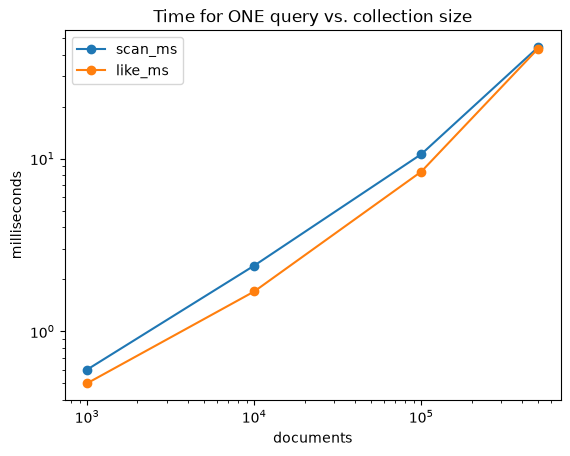

In [31]:
base_texts = list(docs.values())
random.seed(1)

def make_big_corpus(n):
    return [base_texts[i % len(base_texts)] + f" ref{random.randint(0, 10**6)}" for i in range(n)]

sizes = [1_000, 10_000, 100_000, 500_000]
timings = []
for n in sizes:
    corpus = make_big_corpus(n)
    t0 = time.perf_counter()
    scan_hits = [i for i, t in enumerate(corpus) if "rice" in t.lower()]
    scan_ms = (time.perf_counter() - t0) * 1000

    big = sqlite3.connect(":memory:")
    big.execute("CREATE TABLE docs (id INTEGER PRIMARY KEY, text TEXT)")
    big.executemany("INSERT INTO docs(text) VALUES (?)", [(t,) for t in corpus])
    t0 = time.perf_counter()
    like_hits = big.execute("SELECT id FROM docs WHERE text LIKE ?", ("%rice%",)).fetchall()
    like_ms = (time.perf_counter() - t0) * 1000
    timings.append({"documents": n, "scan_ms": round(scan_ms, 1), "like_ms": round(like_ms, 1)})
    print(f"{n:>8,} docs: scan {scan_ms:7.1f} ms, LIKE {like_ms:7.1f} ms")

timing_df = pd.DataFrame(timings)
timing_df.plot(x="documents", y=["scan_ms", "like_ms"], marker="o", logx=True, logy=True,
               title="Time for ONE query vs. collection size")
plt.ylabel("milliseconds"); plt.show()

In [28]:
# TODO: use the LARGEST measurement to estimate how long ONE scan query would take
#       over 1 billion pages, in seconds and in minutes.
largest = timing_df.iloc[-1]
seconds_for_1_billion = (
    (largest["scan_ms"] / 1000) / largest["documents"] * 1_000_000_000
)
minutes_for_1_billion = seconds_for_1_billion / 60

print(seconds_for_1_billion)
print(minutes_for_1_billion)

85.99999999999999
1.4333333333333331


**Answer 6.1** How does the time grow when the collection grows 10 times? What does your estimate say about scanning a web-scale collection for every query?

*Your answer:*

When grows 10 times, the search takes more time. scanning a web-scale collection for every query too slow.


**Answer 6.2** In one or two sentences, how could a system avoid reading every document at query time? (You will build this in Session 2.)

*Your answer:*
We can sort the documents and link them with the key terms or words that reference the collection of documents.

## Part 7. Bonus: Khmer text (optional, 15 min)
Khmer is written without spaces between words. What does that do to the word-based search from Part 3?

In [32]:
pip install khmer-nltk

  Using cached scipy-1.18.1-cp314-cp314-macosx_14_0_arm64.whl.metadata (62 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.0/7.0 MB 3.7 MB/s  0:00:01 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.3/8.3 MB 4.3 MB/s  0:00:01 eta 0:00:01
Using cached scipy-1.18.1-cp314-cp314-macosx_14_0_arm64.whl (20.5 MB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11/11 [khmer-nltk]1 [scikit-learn]

[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [35]:
# khmer_docs = {
#     "k1": 'ភ្នំពេញជារាជធានីនៃប្រទេសកម្ពុជា',
#     "k2": 'អង្គរវត្តជាប្រាសាទដ៏ធំបំផុតក្នុងពិភពលោក',
#     "k3": 'ខ្ញុំចូលចិត្តរៀនសរសេរកម្មវិធី',
# }

# for q in ["រាជធានី", "ប្រទេស", "កម្មវិធី"]:
#     substring_hits = [i for i, t in khmer_docs.items() if q in t]
#     word_hits = [i for i, t in khmer_docs.items() if q in t.split()]
#     print(f"{q}: substring -> {substring_hits} | whole-word (split on spaces) -> {word_hits}")

from khmernltk import word_tokenize

khmer_docs = {
    "k1": "ភ្នំពេញជារាជធានីនៃប្រទេសកម្ពុជា",
    "k2": "អង្គរវត្តជាប្រាសាទដ៏ធំបំផុតក្នុងពិភពលោក",
    "k3": "ខ្ញុំចូលចិត្តរៀនសរសេរកម្មវិធី",
}
for doc_id, text in khmer_docs.items():
    tokens = word_tokenize(text, return_tokens=True)
    print(tokens)

for q in ["រាជធានី", "ប្រទេស", "កម្មវិធី"]:
    word_hits = [
        i for i, t in khmer_docs.items() if q in word_tokenize(t, return_tokens=True)
    ]
    print(f"{q}: whole-word -> {word_hits}")

['ភ្នំពេញ', 'ជា', 'រាជធានី', 'នៃ', 'ប្រទេស', 'កម្ពុជា']
['អង្គរវត្ត', 'ជា', 'ប្រាសាទ', 'ដ៏', 'ធំ', 'បំផុត', 'ក្នុង', 'ពិភពលោក']
['ខ្ញុំ', 'ចូលចិត្ត', 'រៀន', 'សរសេរ', 'កម្មវិធី']
រាជធានី: whole-word -> ['k1']
ប្រទេស: whole-word -> ['k1']
កម្មវិធី: whole-word -> ['k3']


**Answer 7.1** Why does whole-word matching find nothing while substring matching finds the documents? Which risk of substring matching (see Part 2) still applies?

*Your answer:*
Because it is hard to split the words in Khmer (each word wont sepreate by space like english), but substring is the easy one that can compare if a string is contained in a document or not. Substring matching may return irrelevant documents.

**Optional challenge:** install a Khmer word segmenter (for example `pip install khmer-nltk`) and segment the three sentences. Does whole-word matching now work? Check the package documentation for the exact function name.
Yes it work becuse we can split the khmer word from sentence

## Part 8. Reflection (about 10 min)
Write 4 to 6 sentences: *Why is a database query not the same as a search engine? Use at least two results from this lab as evidence, and name one topic from the course roadmap that would fix one of the problems you found.*

*Your reflection:*

A database query retrieves data by matching exact conditions, without understanding the user’s meaning or information need. A search engine is different because it tries to return information that is relevant to the user. For example, searching for “car” returned no results even though documents about “automobile” and “electric vehicles” were relevant. Also, substring search for “cat” returned irrelevant documents containing words such as “catalog,” “category,” and “concatenate.” 
---
### Submission checklist
- [ ] All `# TODO` cells completed and the notebook runs from top to bottom without errors
- [ ] All *Answer* cells written in your own words
- [ ] `judgments` filled in, and disagreements with your partner noted in Answer 5.3
- [ ] Project team formed (names and theme sent to the instructor)
- [ ] Notebook saved as `Lab1_<StudentID>.ipynb` and submitted as instructed